**Notebook 6 — Error Analysis and Model Comparison**

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/NLP"
)

Mounted at /content/drive


**Imports and configurations**

In [2]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

LABEL_IDS = [0, 1, 2, 3, 4, 5, 6]

LABEL_NAMES = [
    "neutral",
    "anger",
    "disgust",
    "fear",
    "happiness",
    "sadness",
    "surprise"
]

ID_TO_LABEL = dict(
    zip(LABEL_IDS, LABEL_NAMES)
)

Defining the project path

In [6]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/NLP"
)

RESULTS_DIR = PROJECT_ROOT / "results"

TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"

ERROR_ANALYSIS_DIR = (
    RESULTS_DIR / "error_analysis"
)

for directory in [
    TABLES_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    ERROR_ANALYSIS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", PROJECT_ROOT)
print("Predictions folder:", PREDICTIONS_DIR)

Project root: /content/drive/MyDrive/NLP
Predictions folder: /content/drive/MyDrive/NLP/results/predictions


locate final prediction files

In [8]:
def find_prediction_file(
    preferred_name,
    search_pattern
):
    preferred_path = (
        PREDICTIONS_DIR / preferred_name
    )

    if preferred_path.exists():
        return preferred_path

    matches = list(
        PROJECT_ROOT.rglob(
            search_pattern
        )
    )

    if not matches:
        raise FileNotFoundError(
            f"Could not find {preferred_name}. "
            f"Search pattern: {search_pattern}"
        )

    if len(matches) > 1:
        print(
            f"Multiple matches found for "
            f"{preferred_name}:"
        )

        for match in matches:
            print(match)

    return matches[0]


SBERT_PREDICTIONS_PATH = (
    find_prediction_file(
        preferred_name=(
            "final_sbert_test_predictions.csv"
        ),
        search_pattern=(
            "*sbert*test*predictions*.csv"
        )
    )
)

TRANSFORMER_PREDICTIONS_PATH = (
    find_prediction_file(
        preferred_name=(
            "final_transformer_test_predictions.csv"
        ),
        search_pattern=(
            "*transformer*test*predictions*.csv"
        )
    )
)

print(
    "Sentence-BERT predictions:",
    SBERT_PREDICTIONS_PATH
)

print(
    "Transformer predictions:",
    TRANSFORMER_PREDICTIONS_PATH
)

Sentence-BERT predictions: /content/drive/MyDrive/NLP/Data/results/predictions/final_sbert_test_predictions.csv
Transformer predictions: /content/drive/MyDrive/NLP/Data/results/predictions/final_transformer_test_predictions.csv


**Load and validate predictions**

In [9]:
sbert_df = pd.read_csv(
    SBERT_PREDICTIONS_PATH
)

transformer_df = pd.read_csv(
    TRANSFORMER_PREDICTIONS_PATH
)

print("Sentence-BERT:", sbert_df.shape)
print("Transformer:", transformer_df.shape)

display(sbert_df.head())
display(transformer_df.head())

Sentence-BERT: (7740, 10)
Transformer: (7740, 10)


,dialogue_id,turn_index,previous_3,utterance,emotion_label,emotion_name,predicted_label,predicted_emotion,correct,selected_context_setting
0,test_00000,0,NaN,"Hey man , you wanna buy some weed ?",0,neutral,0,neutral,True,shuffled_context
1,test_00000,1,"[SPEAKER_A] Hey man , you wanna buy some weed ?",Some what ?,6,surprise,0,neutral,False,shuffled_context
2,test_00000,2,"[SPEAKER_A] Hey man , you wanna buy some weed ...","Weed ! You know ? Pot , Ganja , Mary Jane some...",0,neutral,0,neutral,True,shuffled_context
3,test_00000,3,"[SPEAKER_A] Hey man , you wanna buy some weed ...","Oh , umm , no thanks .",0,neutral,0,neutral,True,shuffled_context
4,test_00000,4,[SPEAKER_B] Some what ? [SEP] [SPEAKER_A] Weed...,I also have blow if you prefer to do a few lin...,0,neutral,0,neutral,True,shuffled_context


,dialogue_id,turn_index,previous_3,utterance,emotion_label,emotion_name,predicted_label,predicted_emotion,correct,selected_experiment
0,test_00000,0,NaN,"Hey man , you wanna buy some weed ?",0,neutral,0,neutral,True,full_context
1,test_00000,1,"[SPEAKER_A] Hey man , you wanna buy some weed ?",Some what ?,6,surprise,0,neutral,False,full_context
2,test_00000,2,"[SPEAKER_A] Hey man , you wanna buy some weed ...","Weed ! You know ? Pot , Ganja , Mary Jane some...",0,neutral,0,neutral,True,full_context
3,test_00000,3,"[SPEAKER_A] Hey man , you wanna buy some weed ...","Oh , umm , no thanks .",0,neutral,0,neutral,True,full_context
4,test_00000,4,[SPEAKER_B] Some what ? [SEP] [SPEAKER_A] Weed...,I also have blow if you prefer to do a few lin...,0,neutral,0,neutral,True,full_context


Validate the required columns:

In [10]:
REQUIRED_COLUMNS = {
    "dialogue_id",
    "turn_index",
    "utterance",
    "emotion_label",
    "emotion_name",
    "predicted_label",
    "predicted_emotion",
    "correct"
}

for model_name, dataframe in {
    "Sentence-BERT": sbert_df,
    "Transformer": transformer_df
}.items():

    missing_columns = (
        REQUIRED_COLUMNS
        - set(dataframe.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{model_name} file is missing: "
            f"{sorted(missing_columns)}"
        )

    dataframe["emotion_label"] = (
        dataframe["emotion_label"]
        .astype(int)
    )

    dataframe["predicted_label"] = (
        dataframe["predicted_label"]
        .astype(int)
    )

    dataframe["correct"] = (
        dataframe["emotion_label"]
        == dataframe["predicted_label"]
    )

print("Prediction files are valid.")

Prediction files are valid.


**Confirming both models evaluated the same test examples**

This is essential for a fair comparison.

In [11]:
merge_keys = [
    "dialogue_id",
    "turn_index"
]

sbert_keys = set(
    map(
        tuple,
        sbert_df[merge_keys].to_numpy()
    )
)

transformer_keys = set(
    map(
        tuple,
        transformer_df[
            merge_keys
        ].to_numpy()
    )
)

if sbert_keys != transformer_keys:
    raise ValueError(
        "The two prediction files do not "
        "contain exactly the same test examples."
    )

print(
    "Both models evaluated the same",
    len(sbert_keys),
    "test examples."
)

Both models evaluated the same 7740 test examples.


**Merging the two prediction files:**


When we "merge" the SBERT and Transformer predictions, we are simply putting their prediction tables side-by-side for the same test utterances.

In [12]:
comparison_df = sbert_df[
    [
        "dialogue_id",
        "turn_index",
        "utterance",
        "emotion_label",
        "emotion_name",
        "predicted_label",
        "predicted_emotion",
        "correct"
    ]
].rename(
    columns={
        "predicted_label":
            "sbert_predicted_label",

        "predicted_emotion":
            "sbert_predicted_emotion",

        "correct":
            "sbert_correct"
    }
)

transformer_columns = transformer_df[
    [
        "dialogue_id",
        "turn_index",
        "predicted_label",
        "predicted_emotion",
        "correct"
    ]
].rename(
    columns={
        "predicted_label":
            "transformer_predicted_label",

        "predicted_emotion":
            "transformer_predicted_emotion",

        "correct":
            "transformer_correct"
    }
)

comparison_df = comparison_df.merge(
    transformer_columns,
    on=merge_keys,
    how="inner",
    validate="one_to_one"
)

print("Merged comparison:", comparison_df.shape)

display(comparison_df.head())

Merged comparison: (7740, 11)


,dialogue_id,turn_index,utterance,emotion_label,emotion_name,sbert_predicted_label,sbert_predicted_emotion,sbert_correct,transformer_predicted_label,transformer_predicted_emotion,transformer_correct
0,test_00000,0,"Hey man , you wanna buy some weed ?",0,neutral,0,neutral,True,0,neutral,True
1,test_00000,1,Some what ?,6,surprise,0,neutral,False,0,neutral,False
2,test_00000,2,"Weed ! You know ? Pot , Ganja , Mary Jane some...",0,neutral,0,neutral,True,0,neutral,True
3,test_00000,3,"Oh , umm , no thanks .",0,neutral,0,neutral,True,0,neutral,True
4,test_00000,4,I also have blow if you prefer to do a few lin...,0,neutral,0,neutral,True,0,neutral,True


**1- Overall model comparison**

Recalculating test metrics consistently

In [13]:
def calculate_model_metrics(
    dataframe,
    prediction_column,
    model_name
):
    y_true = dataframe[
        "emotion_label"
    ].to_numpy()

    y_pred = dataframe[
        prediction_column
    ].to_numpy()

    return {
        "model": model_name,

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="weighted",
            zero_division=0
        )
    }


overall_results = pd.DataFrame([
    calculate_model_metrics(
        comparison_df,
        "sbert_predicted_label",
        "Sentence-BERT"
    ),

    calculate_model_metrics(
        comparison_df,
        "transformer_predicted_label",
        "Fine-tuned Transformer"
    )
])

display(
    overall_results.round(4)
)

overall_results.to_csv(
    ERROR_ANALYSIS_DIR
    / "overall_model_comparison.csv",
    index=False
)

,model,accuracy,macro_f1,weighted_f1
0,Sentence-BERT,0.8021,0.4117,0.8131
1,Fine-tuned Transformer,0.8475,0.5382,0.8503


Calculating the improvement:

In [14]:
sbert_macro_f1 = float(
    overall_results.loc[
        overall_results["model"]
        == "Sentence-BERT",
        "macro_f1"
    ].iloc[0]
)

transformer_macro_f1 = float(
    overall_results.loc[
        overall_results["model"]
        == "Fine-tuned Transformer",
        "macro_f1"
    ].iloc[0]
)

macro_f1_improvement = (
    transformer_macro_f1
    - sbert_macro_f1
)

print(
    "Transformer Macro-F1 improvement:",
    f"{macro_f1_improvement:+.4f}"
)

Transformer Macro-F1 improvement: +0.1266


**2- Per-emotion analysis**


Comparing class-wise precision, recall and F1

In [15]:
def create_per_class_report(
    dataframe,
    prediction_column,
    model_name
):
    report = classification_report(
        dataframe["emotion_label"],
        dataframe[prediction_column],
        labels=LABEL_IDS,
        target_names=LABEL_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = (
        pd.DataFrame(report)
        .transpose()
        .loc[
            LABEL_NAMES,
            [
                "precision",
                "recall",
                "f1-score",
                "support"
            ]
        ]
        .reset_index()
        .rename(
            columns={
                "index": "emotion"
            }
        )
    )

    report_df["model"] = model_name

    return report_df


sbert_class_report = (
    create_per_class_report(
        comparison_df,
        "sbert_predicted_label",
        "Sentence-BERT"
    )
)

transformer_class_report = (
    create_per_class_report(
        comparison_df,
        "transformer_predicted_label",
        "Fine-tuned Transformer"
    )
)

per_class_results = pd.concat(
    [
        sbert_class_report,
        transformer_class_report
    ],
    ignore_index=True
)

display(
    per_class_results.round(4)
)

per_class_results.to_csv(
    ERROR_ANALYSIS_DIR
    / "per_emotion_model_comparison.csv",
    index=False
)

,emotion,precision,recall,f1-score,support,model
0,neutral,0.9101,0.8616,0.8852,6321.0,Sentence-BERT
1,anger,0.2616,0.3814,0.3103,118.0,Sentence-BERT
2,disgust,0.2000,0.2979,0.2393,47.0,Sentence-BERT
3,fear,0.1667,0.3529,0.2264,17.0,Sentence-BERT
4,happiness,0.5410,0.5898,0.5643,1019.0,Sentence-BERT
5,sadness,0.2514,0.4510,0.3228,102.0,Sentence-BERT
6,surprise,0.2717,0.4310,0.3333,116.0,Sentence-BERT
7,neutral,0.9212,0.9006,0.9108,6321.0,Fine-tuned Transformer
8,anger,0.4757,0.4153,0.4434,118.0,Fine-tuned Transformer
9,disgust,0.4848,0.3404,0.4000,47.0,Fine-tuned Transformer


Creating a direct F1 comparison:

In [16]:
f1_comparison = (
    per_class_results.pivot(
        index="emotion",
        columns="model",
        values="f1-score"
    )
    .reset_index()
)

f1_comparison[
    "transformer_improvement"
] = (
    f1_comparison[
        "Fine-tuned Transformer"
    ]
    - f1_comparison[
        "Sentence-BERT"
    ]
)

f1_comparison = (
    f1_comparison.sort_values(
        "transformer_improvement",
        ascending=False
    )
)

display(
    f1_comparison.round(4)
)

f1_comparison.to_csv(
    ERROR_ANALYSIS_DIR
    / "per_emotion_f1_improvement.csv",
    index=False
)

model,emotion,Fine-tuned Transformer,Sentence-BERT,transformer_improvement
2,fear,0.5000,0.2264,0.2736
6,surprise,0.4966,0.3333,0.1633
1,disgust,0.4000,0.2393,0.1607
0,anger,0.4434,0.3103,0.1331
3,happiness,0.6359,0.5643,0.0715
5,sadness,0.3810,0.3228,0.0581
4,neutral,0.9108,0.8852,0.0256


**3- Confusion analysis**

Normalized confusion matrices

In [18]:
def plot_normalized_confusion_matrix(
    dataframe,
    prediction_column,
    model_name,
    output_filename
):
    matrix = confusion_matrix(
        dataframe["emotion_label"],
        dataframe[prediction_column],
        labels=LABEL_IDS,
        normalize="true"
    )

    fig, ax = plt.subplots(
        figsize=(9, 8)
    )

    image = ax.imshow(
        matrix,
        vmin=0,
        vmax=1
    )

    ax.set_xticks(
        range(len(LABEL_NAMES))
    )

    ax.set_xticklabels(
        LABEL_NAMES,
        rotation=45,
        ha="right"
    )

    ax.set_yticks(
        range(len(LABEL_NAMES))
    )

    ax.set_yticklabels(
        LABEL_NAMES
    )

    for row in range(
        matrix.shape[0]
    ):
        for column in range(
            matrix.shape[1]
        ):
            ax.text(
                column,
                row,
                f"{matrix[row, column]:.2f}",
                ha="center",
                va="center"
            )

    ax.set_title(
        f"{model_name}\n"
        "Normalized Test Confusion Matrix"
    )

    ax.set_xlabel(
        "Predicted emotion"
    )

    ax.set_ylabel(
        "True emotion"
    )

    fig.colorbar(image)

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / output_filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return matrix

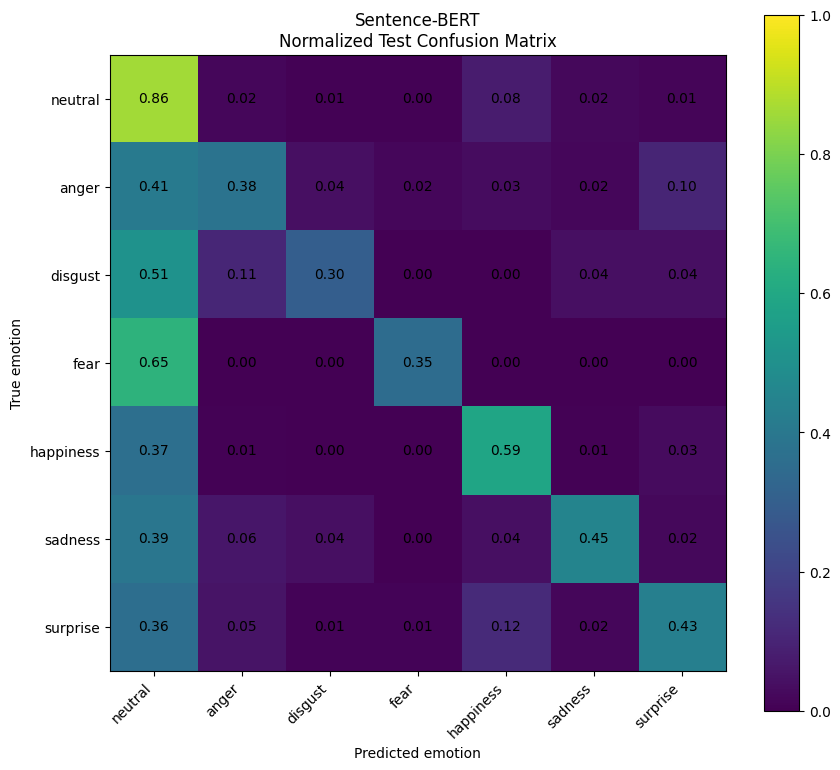

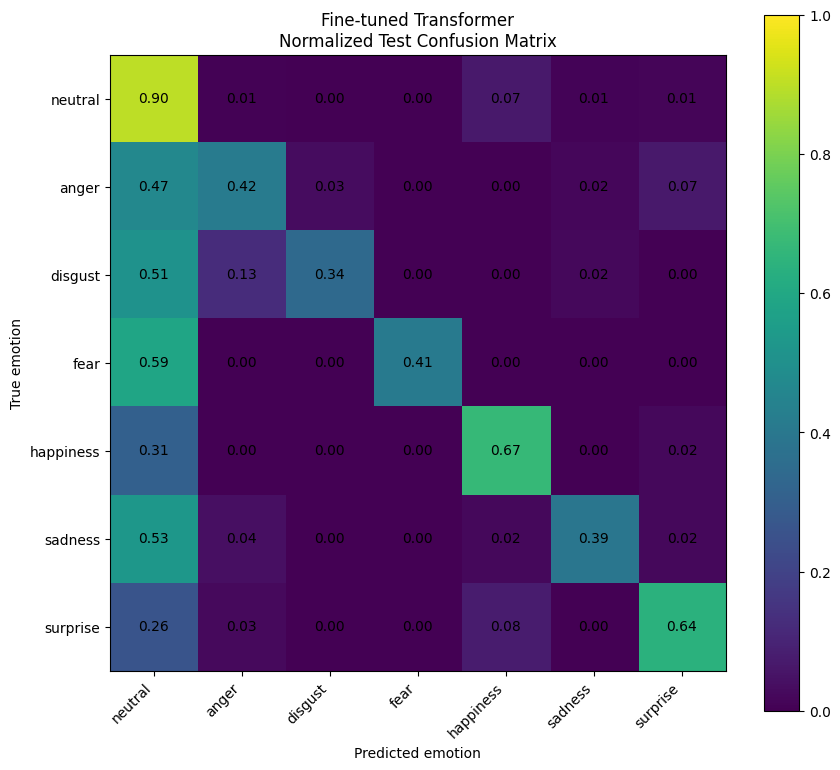

In [19]:
sbert_confusion = (
    plot_normalized_confusion_matrix(
        comparison_df,
        "sbert_predicted_label",
        "Sentence-BERT",
        "sbert_test_normalized_confusion.png"
    )
)

transformer_confusion = (
    plot_normalized_confusion_matrix(
        comparison_df,
        "transformer_predicted_label",
        "Fine-tuned Transformer",
        "transformer_test_normalized_confusion.png"
    )
)

**Extracting the most frequent confusion pairs**

In [20]:
def create_confusion_pairs(
    dataframe,
    prediction_column,
    model_name
):
    matrix = confusion_matrix(
        dataframe["emotion_label"],
        dataframe[prediction_column],
        labels=LABEL_IDS
    )

    rows = []

    for true_index, true_name in enumerate(
        LABEL_NAMES
    ):
        true_support = int(
            matrix[true_index].sum()
        )

        for predicted_index, predicted_name in enumerate(
            LABEL_NAMES
        ):
            if (
                true_index
                == predicted_index
            ):
                continue

            count = int(
                matrix[
                    true_index,
                    predicted_index
                ]
            )

            if count == 0:
                continue

            rows.append({
                "model": model_name,
                "true_emotion": true_name,
                "predicted_emotion":
                    predicted_name,
                "count": count,
                "true_class_support":
                    true_support,
                "percentage_of_true_class":
                    (
                        count / true_support * 100
                        if true_support > 0
                        else 0
                    )
            })

    return pd.DataFrame(rows)


confusion_pairs_df = pd.concat(
    [
        create_confusion_pairs(
            comparison_df,
            "sbert_predicted_label",
            "Sentence-BERT"
        ),

        create_confusion_pairs(
            comparison_df,
            "transformer_predicted_label",
            "Fine-tuned Transformer"
        )
    ],
    ignore_index=True
)

top_confusions = (
    confusion_pairs_df.sort_values(
        [
            "model",
            "count"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "model",
        as_index=False
    )
    .head(10)
)

display(
    top_confusions.round(2)
)

confusion_pairs_df.to_csv(
    ERROR_ANALYSIS_DIR
    / "all_confusion_pairs.csv",
    index=False
)

top_confusions.to_csv(
    ERROR_ANALYSIS_DIR
    / "top_confusion_pairs.csv",
    index=False
)

,model,true_emotion,predicted_emotion,count,true_class_support,percentage_of_true_class
37,Fine-tuned Transformer,neutral,happiness,431,6321,6.82
48,Fine-tuned Transformer,happiness,neutral,314,1019,30.81
39,Fine-tuned Transformer,neutral,surprise,76,6321,1.20
38,Fine-tuned Transformer,neutral,sadness,65,6321,1.03
40,Fine-tuned Transformer,anger,neutral,55,118,46.61
52,Fine-tuned Transformer,sadness,neutral,54,102,52.94
34,Fine-tuned Transformer,neutral,anger,40,6321,0.63
56,Fine-tuned Transformer,surprise,neutral,30,116,25.86
44,Fine-tuned Transformer,disgust,neutral,24,47,51.06
51,Fine-tuned Transformer,happiness,surprise,22,1019,2.16


**4- Where the models agree and disagree**

Categorizing every test prediction

In [21]:
comparison_df[
    "comparison_category"
] = np.select(
    [
        (
            comparison_df["sbert_correct"]
            & comparison_df[
                "transformer_correct"
            ]
        ),

        (
            ~comparison_df["sbert_correct"]
            & comparison_df[
                "transformer_correct"
            ]
        ),

        (
            comparison_df["sbert_correct"]
            & ~comparison_df[
                "transformer_correct"
            ]
        ),

        (
            ~comparison_df["sbert_correct"]
            & ~comparison_df[
                "transformer_correct"
            ]
        )
    ],

    [
        "both_correct",
        "transformer_only_correct",
        "sbert_only_correct",
        "both_wrong"
    ],

    default="unknown"
)

category_summary = (
    comparison_df[
        "comparison_category"
    ]
    .value_counts()
    .rename_axis(
        "category"
    )
    .reset_index(
        name="count"
    )
)

category_summary[
    "percentage"
] = (
    category_summary["count"]
    / len(comparison_df)
    * 100
)

display(
    category_summary.round(2)
)

category_summary.to_csv(
    ERROR_ANALYSIS_DIR
    / "model_agreement_summary.csv",
    index=False
)

,category,count,percentage
0,both_correct,5804,74.99
1,both_wrong,776,10.03
2,transformer_only_correct,756,9.77
3,sbert_only_correct,404,5.22


**Save examples where the transformer improves over SBERT**



In [22]:
transformer_improvement_examples = (
    comparison_df.loc[
        comparison_df[
            "comparison_category"
        ]
        == "transformer_only_correct"
    ]
    .sample(
        n=min(
            20,
            (
                comparison_df[
                    "comparison_category"
                ]
                == "transformer_only_correct"
            ).sum()
        ),
        random_state=SEED
    )
    .copy()
)

transformer_improvement_examples[
    "manual_comment"
] = ""

display(
    transformer_improvement_examples[
        [
            "utterance",
            "emotion_name",
            "sbert_predicted_emotion",
            "transformer_predicted_emotion",
            "manual_comment"
        ]
    ]
)

transformer_improvement_examples.to_csv(
    ERROR_ANALYSIS_DIR
    / "transformer_only_correct_examples.csv",
    index=False
)

,utterance,emotion_name,sbert_predicted_emotion,transformer_predicted_emotion,manual_comment
4677,Very well . I hope you ' ll enjoy your stay in...,neutral,happiness,neutral,
1348,Hey Mel ! Are you up for some tennis today ?,neutral,happiness,neutral,
4859,"Well , there's one thing .",neutral,happiness,neutral,
6238,I didn't know you had a brother .,surprise,neutral,surprise,
6443,You'll never guess what I won at work today ! ...,happiness,neutral,happiness,
969,Wait a minute ! Just hold your horses ! What's...,neutral,anger,neutral,
677,"it'll be sad to see you go , but it sounds lik...",neutral,happiness,neutral,
1426,Thanks . Please sit down . She ’ ll be with yo...,neutral,happiness,neutral,
3825,"Oh well , that's it . They obviously think you...",neutral,surprise,neutral,
5522,"I think we can go to the river , go around and...",happiness,neutral,happiness,


**Save examples where both models fail**

In [23]:
both_wrong_examples = (
    comparison_df.loc[
        comparison_df[
            "comparison_category"
        ]
        == "both_wrong"
    ]
    .sample(
        n=min(
            20,
            (
                comparison_df[
                    "comparison_category"
                ]
                == "both_wrong"
            ).sum()
        ),
        random_state=SEED
    )
    .copy()
)

both_wrong_examples[
    "manual_error_category"
] = ""

both_wrong_examples[
    "manual_comment"
] = ""

display(
    both_wrong_examples[
        [
            "utterance",
            "emotion_name",
            "sbert_predicted_emotion",
            "transformer_predicted_emotion",
            "manual_error_category",
            "manual_comment"
        ]
    ]
)

both_wrong_examples.to_csv(
    ERROR_ANALYSIS_DIR
    / "both_models_wrong_examples.csv",
    index=False
)

,utterance,emotion_name,sbert_predicted_emotion,transformer_predicted_emotion,manual_error_category,manual_comment
5403,"Well , I do have assets in my country . like I...",happiness,neutral,neutral,,
7277,"Oh , yeah , it ’ s terrible . I will tell you ...",neutral,disgust,disgust,,
4590,That's great . What's on tonight ?,neutral,happiness,happiness,,
7635,I can hardly make ends meet these days .,neutral,sadness,sadness,,
4951,I ’ m sorry to say no .,neutral,sadness,sadness,,
6267,"Yes , I'm a very good mother and successful ca...",happiness,neutral,neutral,,
7437,You've been through this too ?,surprise,sadness,neutral,,
2832,Wasn't that football game great ! I just knew ...,happiness,surprise,neutral,,
1812,Thank you .,neutral,happiness,happiness,,
6075,What are you going to do next year ?,happiness,neutral,neutral,,


**5- Performance by utterance length**

Short, medium and long utterances

In [24]:
comparison_df[
    "utterance_word_count"
] = (
    comparison_df["utterance"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

comparison_df[
    "length_group"
] = pd.cut(
    comparison_df[
        "utterance_word_count"
    ],
    bins=[
        -1,
        5,
        15,
        np.inf
    ],
    labels=[
        "short_0_5",
        "medium_6_15",
        "long_16_plus"
    ]
)

In [25]:
length_results = []

for length_group, group in (
    comparison_df.groupby(
        "length_group",
        observed=True
    )
):
    for model_name, prediction_column in {
        "Sentence-BERT":
            "sbert_predicted_label",

        "Fine-tuned Transformer":
            "transformer_predicted_label"
    }.items():

        length_results.append({
            "length_group":
                str(length_group),

            "model":
                model_name,

            "examples":
                len(group),

            "accuracy":
                accuracy_score(
                    group["emotion_label"],
                    group[
                        prediction_column
                    ]
                ),

            "macro_f1":
                f1_score(
                    group["emotion_label"],
                    group[
                        prediction_column
                    ],
                    labels=LABEL_IDS,
                    average="macro",
                    zero_division=0
                )
        })

length_results_df = pd.DataFrame(
    length_results
)

display(
    length_results_df.round(4)
)

length_results_df.to_csv(
    ERROR_ANALYSIS_DIR
    / "performance_by_utterance_length.csv",
    index=False
)

,length_group,model,examples,accuracy,macro_f1
0,short_0_5,Sentence-BERT,1056,0.8144,0.4888
1,short_0_5,Fine-tuned Transformer,1056,0.8466,0.6446
2,medium_6_15,Sentence-BERT,4387,0.8147,0.4102
3,medium_6_15,Fine-tuned Transformer,4387,0.8648,0.5502
4,long_16_plus,Sentence-BERT,2297,0.7723,0.3609
5,long_16_plus,Fine-tuned Transformer,2297,0.8150,0.4599


**6- Performance by dialogue position**

Early versus later dialogue turns

In [26]:
comparison_df[
    "turn_group"
] = pd.cut(
    comparison_df["turn_index"],
    bins=[
        -1,
        0,
        2,
        5,
        np.inf
    ],
    labels=[
        "first_turn",
        "early_turns_2_3",
        "middle_turns_4_6",
        "later_turns_7_plus"
    ]
)

turn_results = []

for turn_group, group in (
    comparison_df.groupby(
        "turn_group",
        observed=True
    )
):
    for model_name, prediction_column in {
        "Sentence-BERT":
            "sbert_predicted_label",

        "Fine-tuned Transformer":
            "transformer_predicted_label"
    }.items():

        turn_results.append({
            "turn_group":
                str(turn_group),

            "model":
                model_name,

            "examples":
                len(group),

            "accuracy":
                accuracy_score(
                    group["emotion_label"],
                    group[
                        prediction_column
                    ]
                ),

            "macro_f1":
                f1_score(
                    group["emotion_label"],
                    group[
                        prediction_column
                    ],
                    labels=LABEL_IDS,
                    average="macro",
                    zero_division=0
                )
        })

turn_results_df = pd.DataFrame(
    turn_results
)

display(
    turn_results_df.round(4)
)

turn_results_df.to_csv(
    ERROR_ANALYSIS_DIR
    / "performance_by_dialogue_position.csv",
    index=False
)

,turn_group,model,examples,accuracy,macro_f1
0,first_turn,Sentence-BERT,1000,0.8350,0.4264
1,first_turn,Fine-tuned Transformer,1000,0.8790,0.5382
2,early_turns_2_3,Sentence-BERT,1958,0.8059,0.3823
3,early_turns_2_3,Fine-tuned Transformer,1958,0.8529,0.4901
4,middle_turns_4_6,Sentence-BERT,2310,0.8048,0.4336
5,middle_turns_4_6,Fine-tuned Transformer,2310,0.8537,0.6143
6,later_turns_7_plus,Sentence-BERT,2472,0.7832,0.3903
7,later_turns_7_plus,Fine-tuned Transformer,2472,0.8248,0.4853


**7- Class imbalance and error rates**

Comparing support with model performance

In [27]:
class_support = (
    comparison_df[
        "emotion_name"
    ]
    .value_counts()
    .reindex(
        LABEL_NAMES,
        fill_value=0
    )
    .rename_axis(
        "emotion"
    )
    .reset_index(
        name="test_support"
    )
)

support_performance_df = (
    class_support.merge(
        f1_comparison,
        on="emotion",
        how="left"
    )
)

display(
    support_performance_df.round(4)
)

support_performance_df.to_csv(
    ERROR_ANALYSIS_DIR
    / "class_support_and_f1.csv",
    index=False
)

,emotion,test_support,Fine-tuned Transformer,Sentence-BERT,transformer_improvement
0,neutral,6321,0.9108,0.8852,0.0256
1,anger,118,0.4434,0.3103,0.1331
2,disgust,47,0.4000,0.2393,0.1607
3,fear,17,0.5000,0.2264,0.2736
4,happiness,1019,0.6359,0.5643,0.0715
5,sadness,102,0.3810,0.3228,0.0581
6,surprise,116,0.4966,0.3333,0.1633


**Context-sensitive examples**

In [49]:
no_context_predictions = sbert_df.copy()
context_predictions = transformer_df.copy()

context_comparison = (
    no_context_predictions[
        [
            "dialogue_id",
            "turn_index",
            "emotion_label",
            "predicted_label"
        ]
    ]
    .rename(
        columns={
            "predicted_label":
                "no_context_prediction"
        }
    )
    .merge(
        context_predictions[
            [
                "dialogue_id",
                "turn_index",
                "predicted_label"
            ]
        ],
        on=[
            "dialogue_id",
            "turn_index"
        ],
        suffixes=(
            "_no_context",
            "_context"
        )
    )
)

In [52]:
context_comparison[
    "context_changed_prediction"
] = (
    context_comparison[
        "no_context_prediction"
    ]
    !=
    context_comparison[
        "predicted_label"
    ]
)

changed = context_comparison[
    "context_changed_prediction"
].sum()

total = len(context_comparison)

print(
    f"Predictions changed: {changed:,} "
    f"out of {total:,}"
)

print(
    f"Percentage changed: "
    f"{100 * changed / total:.2f}%"
)


Predictions changed: 1,267 out of 7,740
Percentage changed: 16.37%


**Context usefulness analysis**

In [47]:
context_comparison[
    "no_context_correct"
] = (
    context_comparison[
        "no_context_prediction"
    ]
    ==
    context_comparison[
        "emotion_label"
    ]
)

context_comparison[
    "context_correct"
] = (
    context_comparison[
        "predicted_label"
    ]
    ==
    context_comparison[
        "emotion_label"
    ]
)

context_improved = (
    (~context_comparison["no_context_correct"])
    &
    (context_comparison["context_correct"])
).sum()

context_hurt = (
    (context_comparison["no_context_correct"])
    &
    (~context_comparison["context_correct"])
).sum()

unchanged_correct = (
    context_comparison["no_context_correct"]
    &
    context_comparison["context_correct"]
).sum()

unchanged_wrong = (
    (~context_comparison["no_context_correct"])
    &
    (~context_comparison["context_correct"])
).sum()

print("Context usefulness analysis")
print("-" * 50)

print(
    "Context improved:",
    context_improved
)

print(
    "Context hurt:",
    context_hurt
)

print(
    "Correct in both:",
    unchanged_correct
)

print(
    "Wrong in both:",
    unchanged_wrong
)

Context usefulness analysis
--------------------------------------------------
Context improved: 756
Context hurt: 404
Correct in both: 5804
Wrong in both: 776


**Context-sensitive examples**

This directly supports the research question:
"Does conversational context improve emotion recognition?"

In [45]:
context_helped = context_comparison[
    (
        context_comparison[
            "no_context_prediction"
        ]
        !=
        context_comparison[
            "emotion_label"
        ]
    )
    &
    (
        context_comparison[
            "predicted_label"
        ]
        ==
        context_comparison[
            "emotion_label"
        ]
    )
]

display(
    context_helped.head(20)
)

,dialogue_id,turn_index,emotion_label,no_context_prediction,predicted_label,context_changed_prediction
58,test_00006,3,0,5,0,True
59,test_00006,4,0,5,0,True
60,test_00006,5,0,5,0,True
76,test_00007,9,0,4,0,True
89,test_00009,1,0,4,0,True
93,test_00009,5,0,4,0,True
99,test_00010,3,0,5,0,True
108,test_00012,3,0,5,0,True
131,test_00015,12,0,4,0,True
138,test_00016,3,0,5,0,True


**8- Final automatic summary**

Generating key findings

In [31]:
best_transformer_class = (
    transformer_class_report
    .sort_values(
        "f1-score",
        ascending=False
    )
    .iloc[0]
)

worst_transformer_class = (
    transformer_class_report
    .sort_values(
        "f1-score",
        ascending=True
    )
    .iloc[0]
)

largest_improvement_class = (
    f1_comparison.iloc[0]
)

both_wrong_count = int(
    (
        comparison_df[
            "comparison_category"
        ]
        == "both_wrong"
    ).sum()
)

transformer_only_count = int(
    (
        comparison_df[
            "comparison_category"
        ]
        == "transformer_only_correct"
    ).sum()
)

summary = f"""
NOTEBOOK 6 — ERROR ANALYSIS and comparision SUMMARY

Sentence-BERT Macro-F1:
{sbert_macro_f1:.4f}

Transformer Macro-F1:
{transformer_macro_f1:.4f}

Transformer improvement:
{macro_f1_improvement:+.4f}

Strongest Transformer class:
{best_transformer_class['emotion']}
(F1={best_transformer_class['f1-score']:.4f})

Weakest Transformer class:
{worst_transformer_class['emotion']}
(F1={worst_transformer_class['f1-score']:.4f})

Largest class-level Transformer improvement:
{largest_improvement_class['emotion']}
(improvement={largest_improvement_class['transformer_improvement']:+.4f})

Examples corrected only by Transformer:
{transformer_only_count}

Examples missed by both models:
{both_wrong_count}
"""

print(summary)

with open(
    ERROR_ANALYSIS_DIR
    / "error_analysis_summary.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(summary)


NOTEBOOK 6 — ERROR ANALYSIS and comparision SUMMARY

Sentence-BERT Macro-F1:
0.4117

Transformer Macro-F1:
0.5382

Transformer improvement:
+0.1266

Strongest Transformer class:
neutral
(F1=0.9108)

Weakest Transformer class:
sadness
(F1=0.3810)

Largest class-level Transformer improvement:
fear
(improvement=+0.2736)

Examples corrected only by Transformer:
756

Examples missed by both models:
776

